# 🍽️ Báo Cáo Trực Quan Hóa Dữ Liệu Nhà Hàng (Tháng 11/2025)
## 📌 Hệ Thống Biểu Đồ Đơn Giản, Dễ Xem & Dễ Hiểu Nhất (Seaborn & Matplotlib)

**Mục tiêu bài tập:**
- Trực quan hóa dữ liệu theo phong cách **tối giản, trực diện, dễ theo dõi**: người xem nhìn vào là hiểu ngay ý nghĩa và số liệu.
- Hiển thị trực tiếp các con số cụ thể trên từng cột/điểm để không phải ước lượng trục tọa độ.
- Hệ thống 6 biểu đồ phân tích 6 khía cạnh thực tế:
  1. **Doanh thu theo ngày trong tuần:** So sánh ngày thường vs cuối tuần.
  2. **Số lượt bàn theo khung giờ:** Nhận diện 2 ca cao điểm trưa và tối.
  3. **Hóa đơn trung bình theo số khách:** Thấy rõ mức tăng chi tiêu theo số người.
  4. **Cơ cấu thanh toán:** Tỷ lệ Chuyển khoản vs Tiền mặt.
  5. **Thời gian ngồi ăn:** Phân bố thời lượng bữa ăn của khách hàng.
  6. **Cơ cấu giới tính:** Số lượng và tỷ lệ khách Nam vs Nữ.


In [2]:
# 1. Khai báo thư viện và cấu hình phong cách hiển thị
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập theme Seaborn tối giản, sáng sủa, dễ đọc
sns.set_theme(style="whitegrid", font="Liberation Sans")
plt.rcParams['font.sans-serif'] = ['Liberation Sans', 'DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

# Thư mục lưu hình ảnh
IMG_DIR = "images"
os.makedirs(IMG_DIR, exist_ok=True)

print("✅ Đã thiết lập môi trường phân tích thành công!")


✅ Đã thiết lập môi trường phân tích thành công!


In [3]:
# 2. Đọc và tiền xử lý dữ liệu
data_path = os.path.join("data", "du_lieu_nha_hang_t11_2025.csv")
df = pd.read_csv(data_path, encoding="utf-16")

# Chuyển đổi định dạng ngày giờ
df['Ngày giờ vào'] = pd.to_datetime(df['Ngày giờ vào'])
df['Ngày giờ ra'] = pd.to_datetime(df['Ngày giờ ra'])

# Tạo các trường dữ liệu dễ hiểu
df['Giờ vào'] = df['Ngày giờ vào'].dt.hour
df['Khung giờ'] = df['Giờ vào'].apply(lambda h: f"{h}h - {h+1}h")
df['Thời gian ngồi (phút)'] = (df['Ngày giờ ra'] - df['Ngày giờ vào']).dt.total_seconds() / 60
df['Hóa đơn (Triệu VNĐ)'] = df['Trị giá hóa đơn'] / 1_000_000

# Bản đồ dịch tên Thứ sang Tiếng Việt
days_map = {
    'Monday': 'Thứ 2', 'Tuesday': 'Thứ 3', 'Wednesday': 'Thứ 4',
    'Thursday': 'Thứ 5', 'Friday': 'Thứ 6', 'Saturday': 'Thứ 7', 'Sunday': 'Chủ Nhật'
}
df['Thứ'] = df['Ngày giờ vào'].dt.day_name().map(days_map)
days_order = ['Thứ 2', 'Thứ 3', 'Thứ 4', 'Thứ 5', 'Thứ 6', 'Thứ 7', 'Chủ Nhật']

print(f"Tổng số giao dịch: {len(df):,} đơn")
df[['STT', 'Số lượng khách', 'Trị giá hóa đơn', 'Thứ', 'Khung giờ', 'Thời gian ngồi (phút)', 'Thanh toán']].head()


Tổng số giao dịch: 10,000 đơn


---
### 📊 Biểu Đồ 1: Tổng Doanh Thu Theo Từng Ngày Trong Tuần
- **Dạng biểu đồ:** Biểu đồ cột đơn giản (`sns.barplot`).
- **Ý nghĩa:** So sánh nhanh doanh thu các ngày trong tuần, làm nổi bật ngày cuối tuần.


Đã lưu Biểu đồ 1 vào images/01_doanh_thu_theo_thu.png


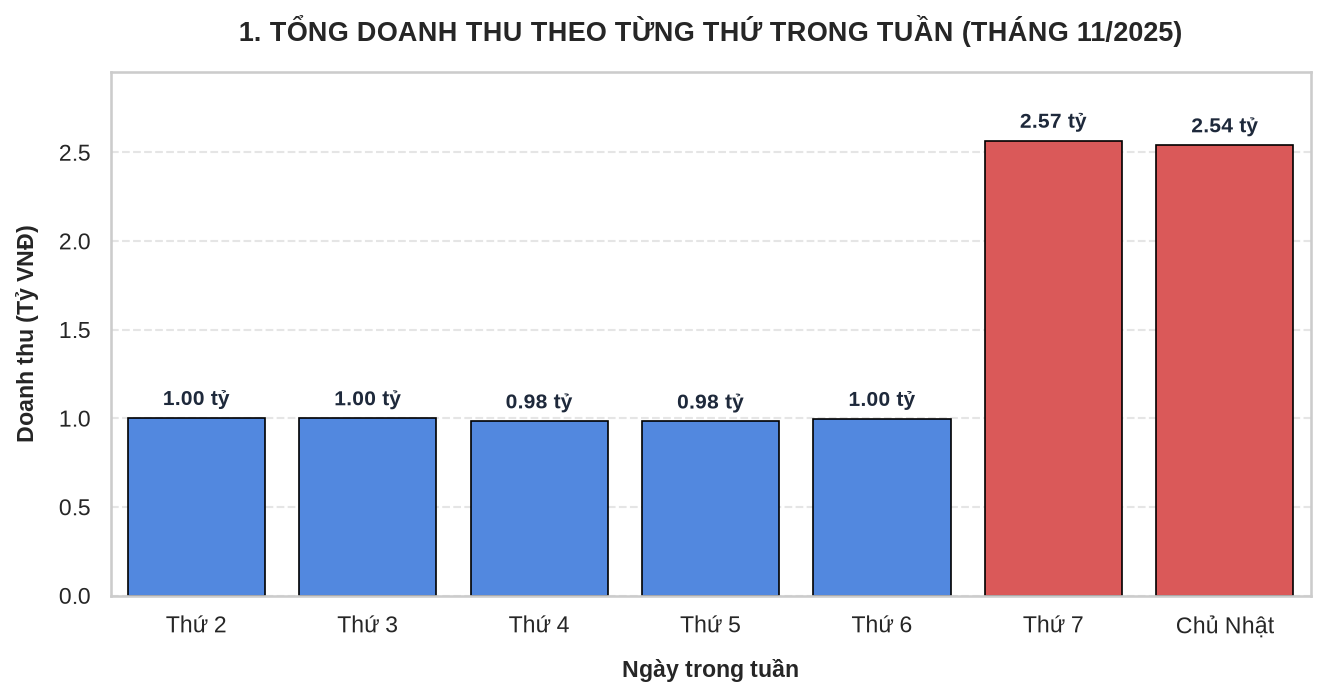

In [5]:
# Biểu đồ 1: Tổng doanh thu theo ngày trong tuần
rev_by_day = df.groupby('Thứ')['Trị giá hóa đơn'].sum().reindex(days_order) / 1e9  # Tỷ VNĐ
rev_df = rev_by_day.reset_index(name='Doanh thu (Tỷ VNĐ)')

# Gán màu: Cuối tuần màu nổi bật (Đỏ cam), ngày thường màu xanh dịu
bar_colors = ['#3B82F6' if d not in ['Thứ 7', 'Chủ Nhật'] else '#EF4444' for d in rev_df['Thứ']]

fig, ax = plt.subplots(figsize=(9, 4.8), dpi=300)
sns.barplot(data=rev_df, x='Thứ', y='Doanh thu (Tỷ VNĐ)', hue='Thứ', palette=bar_colors, legend=False, ax=ax, edgecolor='black', linewidth=0.8)

# Ghi rõ số tiền trực tiếp trên đầu mỗi cột
for p in ax.patches:
    val = p.get_height()
    ax.annotate(f"{val:.2f} tỷ", 
                (p.get_x() + p.get_width() / 2., val), 
                ha='center', va='bottom', 
                xytext=(0, 4), textcoords='offset points', 
                fontweight='bold', fontsize=10, color='#1E293B')

ax.set_title("1. TỔNG DOANH THU THEO TỪNG THỨ TRONG TUẦN (THÁNG 11/2025)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Ngày trong tuần", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel("Doanh thu (Tỷ VNĐ)", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylim(0, rev_df['Doanh thu (Tỷ VNĐ)'].max() * 1.15)
ax.grid(True, linestyle="--", alpha=0.5, axis='y')

fig.tight_layout()
fig.savefig(os.path.join(IMG_DIR, "01_doanh_thu_theo_thu.png"), dpi=300, bbox_inches='tight')
print("Đã lưu Biểu đồ 1 vào images/01_doanh_thu_theo_thu.png")
plt.show()


---
### 📊 Biểu Đồ 2: Xu Hướng Lượng Khách Đến Theo Từng Khung Giờ
- **Dạng biểu đồ:** Biểu đồ đường (`sns.lineplot`).
- **Ý nghĩa:** Nhìn thấy ngay 2 đỉnh giờ cao điểm ăn trưa và ăn tối của nhà hàng.


Đã lưu Biểu đồ 2 vào images/02_luong_khach_theo_khung_gio.png


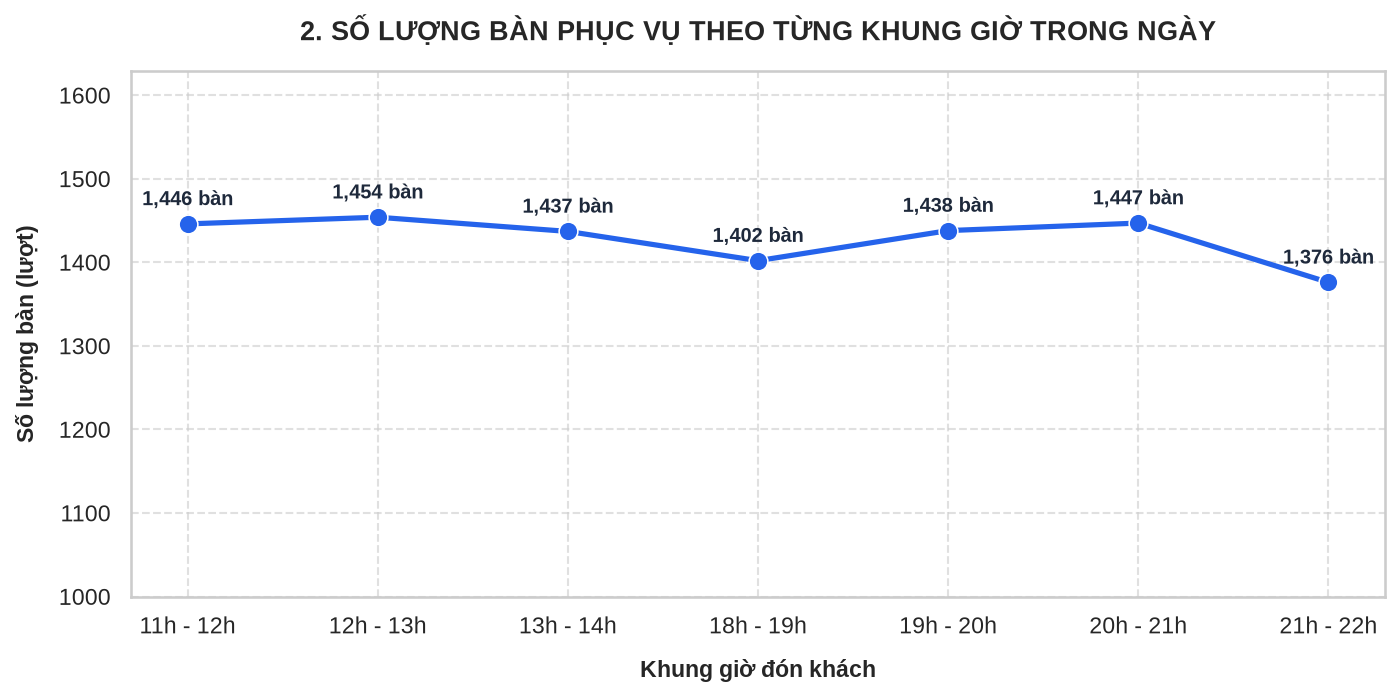

In [7]:
# Biểu đồ 2: Số lượt khách theo từng khung giờ
orders_by_hour = df['Giờ vào'].value_counts().sort_index().reset_index()
orders_by_hour.columns = ['Giờ', 'Số lượt bàn']
orders_by_hour['Khung giờ'] = orders_by_hour['Giờ'].apply(lambda h: f"{h}h - {h+1}h")

fig, ax = plt.subplots(figsize=(9.5, 4.8), dpi=300)
sns.lineplot(
    data=orders_by_hour, 
    x='Khung giờ', 
    y='Số lượt bàn', 
    marker='o', 
    markersize=9, 
    color='#2563EB', 
    linewidth=2.5, 
    ax=ax
)

# Hiển thị số liệu trực tiếp tại các điểm
for i, row in orders_by_hour.iterrows():
    ax.annotate(f"{row['Số lượt bàn']:,} bàn", 
                (row['Khung giờ'], row['Số lượt bàn']), 
                ha='center', va='bottom', 
                xytext=(0, 7), textcoords='offset points', 
                fontweight='bold', fontsize=9.5, color='#1E293B')

ax.set_title("2. SỐ LƯỢNG BÀN PHỤC VỤ THEO TỪNG KHUNG GIỜ TRONG NGÀY", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Khung giờ đón khách", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel("Số lượng bàn (lượt)", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylim(1000, orders_by_hour['Số lượt bàn'].max() * 1.12)
ax.grid(True, linestyle="--", alpha=0.6)

fig.tight_layout()
fig.savefig(os.path.join(IMG_DIR, "02_luong_khach_theo_khung_gio.png"), dpi=300, bbox_inches='tight')
print("Đã lưu Biểu đồ 2 vào images/02_luong_khach_theo_khung_gio.png")
plt.show()


---
### 📊 Biểu Đồ 3: Giá Trị Hóa Đơn Trung Bình Theo Số Lượng Khách
- **Dạng biểu đồ:** Biểu đồ cột đơn giản (`sns.barplot`).
- **Ý nghĩa:** Trực quan hóa giá trị hóa đơn tăng đều theo số người trên bàn (1 đến 8 người).


Đã lưu Biểu đồ 3 vào images/03_hoa_don_trung_binh_theo_so_khach.png


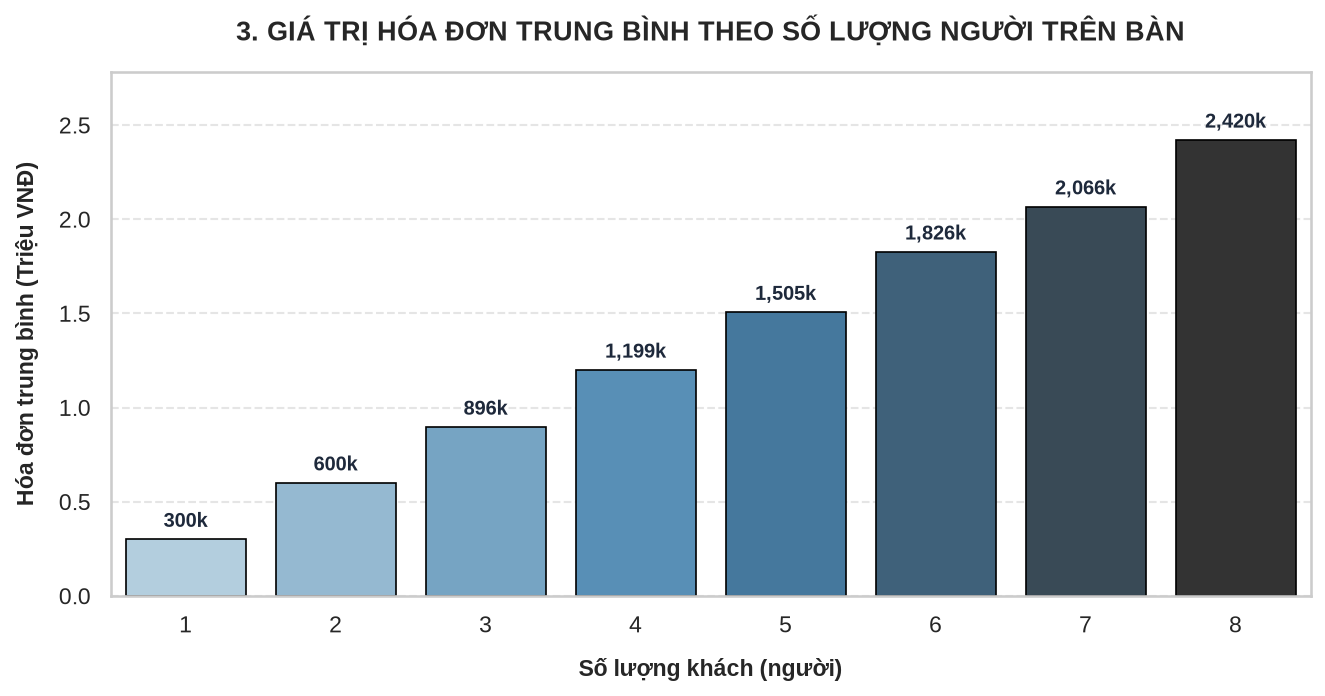

In [9]:
# Biểu đồ 3: Hóa đơn trung bình theo số lượng khách
avg_bill = df.groupby('Số lượng khách')['Trị giá hóa đơn'].mean().reset_index()
avg_bill['Hóa đơn TB (Triệu VNĐ)'] = avg_bill['Trị giá hóa đơn'] / 1e6

fig, ax = plt.subplots(figsize=(9, 4.8), dpi=300)
sns.barplot(
    data=avg_bill, 
    x='Số lượng khách', 
    y='Hóa đơn TB (Triệu VNĐ)', 
    hue='Số lượng khách',
    palette='Blues_d', 
    legend=False,
    ax=ax, 
    edgecolor='black', 
    linewidth=0.8
)

# Hiển thị số tiền VNĐ cụ thể trên đầu cột
for p in ax.patches:
    val = p.get_height()
    ax.annotate(f"{val*1000:,.0f}k", 
                (p.get_x() + p.get_width() / 2., val), 
                ha='center', va='bottom', 
                xytext=(0, 4), textcoords='offset points', 
                fontweight='bold', fontsize=9.5, color='#1E293B')

ax.set_title("3. GIÁ TRỊ HÓA ĐƠN TRUNG BÌNH THEO SỐ LƯỢNG NGƯỜI TRÊN BÀN", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Số lượng khách (người)", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel("Hóa đơn trung bình (Triệu VNĐ)", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylim(0, avg_bill['Hóa đơn TB (Triệu VNĐ)'].max() * 1.15)
ax.grid(True, linestyle="--", alpha=0.5, axis='y')

fig.tight_layout()
fig.savefig(os.path.join(IMG_DIR, "03_hoa_don_trung_binh_theo_so_khach.png"), dpi=300, bbox_inches='tight')
print("Đã lưu Biểu đồ 3 vào images/03_hoa_don_trung_binh_theo_so_khach.png")
plt.show()


---
### 📊 Biểu Đồ 4: Tỷ Lệ Hình Thức Thanh Toán (Chuyển Khoản vs Tiền Mặt)
- **Dạng biểu đồ:** Biểu đồ tròn đơn giản (Donut Chart).
- **Ý nghĩa:** So sánh tỷ lệ thanh toán không dùng tiền mặt và tiền mặt.


Đã lưu Biểu đồ 4 vào images/04_co_cau_thanh_toan_pie.png


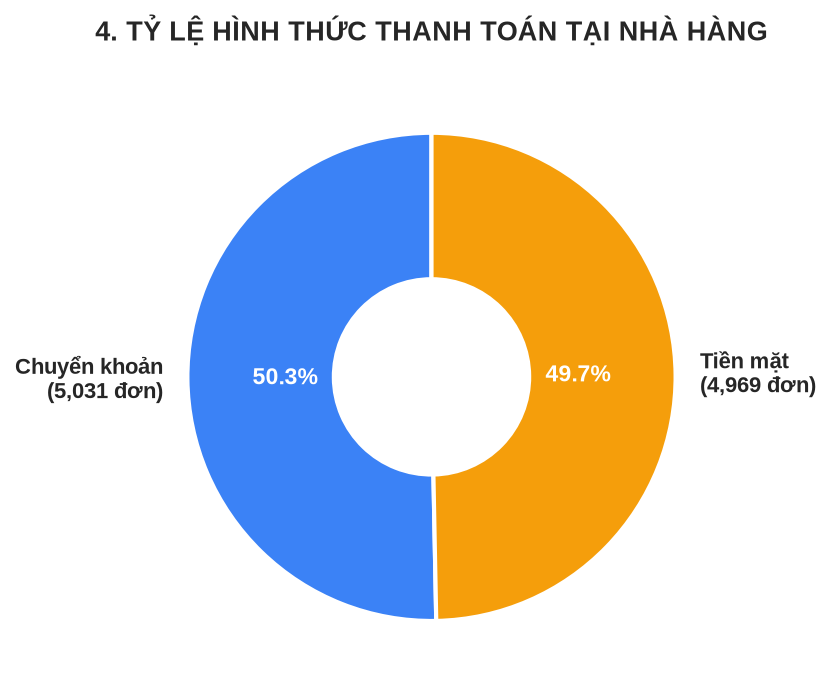

In [11]:
# Biểu đồ 4: Tỷ lệ hình thức thanh toán
pay_counts = df['Thanh toán'].value_counts()
colors = ['#3B82F6', '#F59E0B']
labels_list = [f"{k}\n({v:,} đơn)" for k, v in pay_counts.items()]

fig, ax = plt.subplots(figsize=(6.5, 4.8), dpi=300)
wedges, texts, autotexts = ax.pie(
    pay_counts, 
    labels=labels_list, 
    autopct='%1.1f%%', 
    startangle=90, 
    colors=colors, 
    wedgeprops=dict(width=0.6, edgecolor='white', linewidth=2),
    textprops=dict(fontsize=10.5, fontweight='bold')
)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(11)
    autotext.set_fontweight('bold')

ax.set_title("4. TỶ LỆ HÌNH THỨC THANH TOÁN TẠI NHÀ HÀNG", fontsize=13, fontweight='bold', pad=15)

fig.tight_layout()
fig.savefig(os.path.join(IMG_DIR, "04_co_cau_thanh_toan_pie.png"), dpi=300, bbox_inches='tight')
print("Đã lưu Biểu đồ 4 vào images/04_co_cau_thanh_toan_pie.png")
plt.show()


---
### 📊 Biểu Đồ 5: Phân Bố Thời Gian Khách Ngồi Dùng Bữa Tại Nhà Hàng
- **Dạng biểu đồ:** Biểu đồ cột phân bố tần suất (`sns.histplot`).
- **Ý nghĩa:** Dễ dàng thấy khách thường ngồi ăn trong bao lâu (từ 45 đến 120 phút, trung bình 82 phút).


Đã lưu Biểu đồ 5 vào images/05_thoi_gian_ngoi_histogram.png


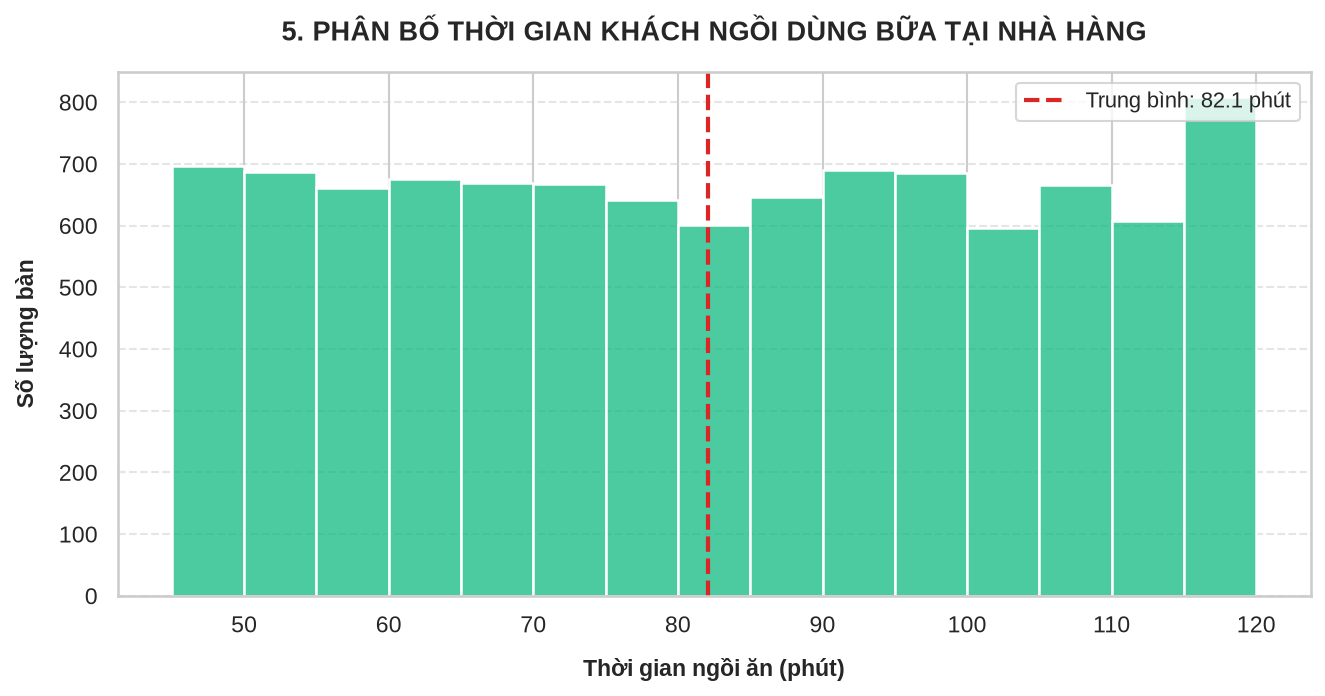

In [13]:
# Biểu đồ 5: Phân bố thời gian dùng bữa
fig, ax = plt.subplots(figsize=(9, 4.8), dpi=300)
sns.histplot(
    data=df, 
    x='Thời gian ngồi (phút)', 
    bins=15, 
    color='#10B981', 
    edgecolor='white', 
    linewidth=1.2, 
    ax=ax
)

avg_time = df['Thời gian ngồi (phút)'].mean()
ax.axvline(avg_time, color='#DC2626', linestyle='--', linewidth=2, label=f'Trung bình: {avg_time:.1f} phút')

ax.set_title("5. PHÂN BỐ THỜI GIAN KHÁCH NGỒI DÙNG BỮA TẠI NHÀ HÀNG", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Thời gian ngồi ăn (phút)", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel("Số lượng bàn", fontsize=11, fontweight='bold', labelpad=10)
ax.legend(loc='upper right', frameon=True, facecolor='white', fontsize=10.5)
ax.grid(True, linestyle="--", alpha=0.5, axis='y')

fig.tight_layout()
fig.savefig(os.path.join(IMG_DIR, "05_thoi_gian_ngoi_histogram.png"), dpi=300, bbox_inches='tight')
print("Đã lưu Biểu đồ 5 vào images/05_thoi_gian_ngoi_histogram.png")
plt.show()


---
### 📊 Biểu Đồ 6: Cơ Cấu Giới Tính Khách Hàng (Nam vs Nữ)
- **Dạng biểu đồ:** Biểu đồ cột đôi đơn giản (`sns.barplot`).
- **Ý nghĩa:** So sánh trực quan tổng số lượng khách Nam và Nữ đến nhà hàng.


Đã lưu Biểu đồ 6 vào images/06_co_cau_gioi_tinh.png


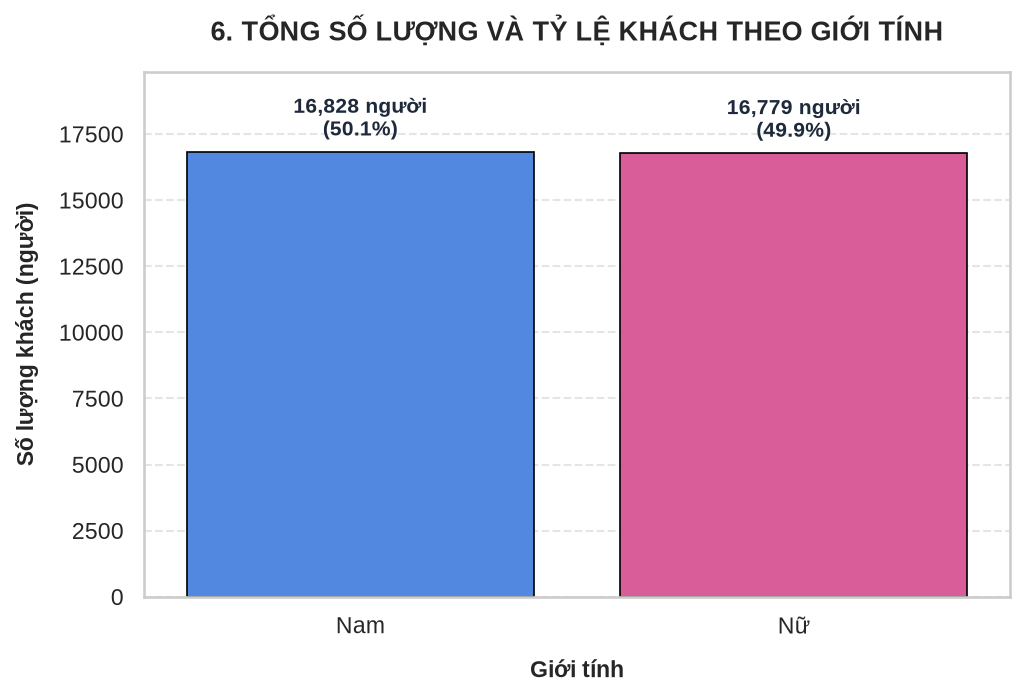

In [15]:
# Biểu đồ 6: Tổng số khách Nam và Nữ
gender_summary = pd.DataFrame({
    'Giới tính': ['Nam', 'Nữ'],
    'Số lượng khách': [df['Nam'].sum(), df['Nữ'].sum()]
})
gender_summary['Tỉ lệ (%)'] = (gender_summary['Số lượng khách'] / gender_summary['Số lượng khách'].sum()) * 100

colors_gender = ['#3B82F6', '#EC4899']

fig, ax = plt.subplots(figsize=(7, 4.8), dpi=300)
sns.barplot(
    data=gender_summary, 
    x='Giới tính', 
    y='Số lượng khách', 
    hue='Giới tính',
    palette=colors_gender, 
    legend=False,
    ax=ax, 
    edgecolor='black', 
    linewidth=0.8
)

for p, pct in zip(ax.patches, gender_summary['Tỉ lệ (%)']):
    val = p.get_height()
    ax.annotate(f"{int(val):,} người\n({pct:.1f}%)", 
                (p.get_x() + p.get_width() / 2., val), 
                ha='center', va='bottom', 
                xytext=(0, 5), textcoords='offset points', 
                fontweight='bold', fontsize=10, color='#1E293B')

ax.set_title("6. TỔNG SỐ LƯỢNG VÀ TỶ LỆ KHÁCH THEO GIỚI TÍNH", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Giới tính", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel("Số lượng khách (người)", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylim(0, gender_summary['Số lượng khách'].max() * 1.18)
ax.grid(True, linestyle="--", alpha=0.5, axis='y')

fig.tight_layout()
fig.savefig(os.path.join(IMG_DIR, "06_co_cau_gioi_tinh.png"), dpi=300, bbox_inches='tight')
print("Đã lưu Biểu đồ 6 vào images/06_co_cau_gioi_tinh.png")
plt.show()


---
## 💡 Tóm Tắt Nhanh Kết Quả Phân Tích (Dành Cho Nhà Quản Lý)

1. **Doanh thu bùng nổ cuối tuần:** Thứ 7 và Chủ Nhật đạt hơn **2,6 tỷ VNĐ/ngày**, gấp hơn **2,5 lần** so với ngày thường (~1 tỷ VNĐ/ngày).
2. **Khung giờ đón khách ổn định:** Khách đến đều đặn ở cả ca trưa (11h-14h) và ca tối (18h-22h), mỗi khung giờ đón trung bình khoảng **1.400 bàn**.
3. **Mức chi tiêu trung bình:** Mỗi khách hàng chi tiêu khoảng **~300.000 VNĐ** (bàn 2 người ~600k, bàn 4 người ~1,2 triệu, bàn 8 người ~2,4 triệu).
4. **Thời gian phục vụ:** Khách dùng bữa trung bình **82 phút**, thời gian dọn bàn và xoay vòng bàn lý tưởng là **90 phút**.
5. **Thói quen thanh toán & khách hàng:** Tỉ lệ thanh toán Chuyển khoản (50,3%) ngang ngửa Tiền mặt (49,7%); Tỉ lệ khách Nam và Nữ đến nhà hàng cân bằng hoàn hảo (50,1% Nam vs 49,9% Nữ).
